This notebook reproduces Fig. 12.

We compare the $(\alpha,\beta)$-hypergeometric pulses with two numerical optimal-control techniques, CRAB and GRAPE, as implemented in `qutip-qtrl`, for the Landau-Zener problem $\hat{H}=z(t)\hat{\sigma}_z+x\hat{\sigma}_x$. Both algorithms optimize a piecewise-constant pulse with `n_ts` time slices and amplitude $|z(t)|\leq 10\,x$, to transfer the state $|0\rangle$ into $|1\rangle$ (the eigenstates of $\hat{\sigma}_z$) for a fixed total time $t_\mathrm{f}$. CRAB uses a Fourier basis with 6 coefficients modulating a linear guess pulse, while GRAPE starts from a linear pulse. As a representative example of the hypergeometric pulses, we use the geometric fast-QUAD, $(\alpha,\beta)=(2,2)$, with boundary conditions $z(t=0)=-z(t=t_\mathrm{f})=-10\,x$.

Note that CRAB uses random initial coefficients, so the results may slightly change between different runs.

Here, we use dimensionless units, with energies in units of $x$, times in units of $\hbar/x$, and frequencies in units of $x/\hbar$. We show the pulses for $t_\mathrm{f}=2\,\hbar/x$ and $t_\mathrm{f}=10\,\hbar/x$, and their Fourier transform. While the hypergeometric pulse shape is independent of the total time, the CRAB and GRAPE pulses must be recomputed for each $t_\mathrm{f}$.

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import qutip as qt
import qutip_qtrl.pulseoptim as cpo

from HQUAD_lib.plotting_utils import add_labels
from HQUAD_lib.QUAD_utils import solve_LZ

In [2]:
x = 1
n_ts = 1000  # Time slices
amp_lbound, amp_ubound = -10.0, 10.0

psi0 = qt.basis(2, 0)
psit = qt.basis(2, 1)

H_d = x * qt.sigmax()  # Drift
H_c = qt.sigmaz()  # Control

tfs_target = [2, 10]

CRAB_color = "lightskyblue"
GRAPE_color = "mediumpurple"
geometric_color = "indigo"

In [3]:
def solve_CRAB(tf: float, H_d: qt.Qobj, H_c: qt.Qobj) -> np.ndarray:
    res = cpo.opt_pulse_crab(
        drift=H_d,
        ctrls=[H_c],
        initial=psi0,
        target=psit,
        num_tslots=n_ts,
        evo_time=tf,
        amp_lbound=amp_lbound,
        amp_ubound=amp_ubound,
        fid_err_targ=1e-20,
        max_iter=500,
        num_coeffs=6,
        guess_pulse_type="LIN",
        init_coeff_scaling=amp_ubound,
        prop_type="DIAG",
        dyn_type="UNIT",
        fid_type="UNIT",
        fid_params={"phase_option": "PSU"},
        log_level=0,
        gen_stats=False,
    )
    return res.final_amps[:, 0]


def solve_GRAPE(tf: float, H_d: qt.Qobj, H_c: qt.Qobj) -> np.ndarray:
    res = cpo.optimize_pulse(
        drift=H_d,
        ctrls=[H_c],
        initial=psi0,
        target=psit,
        num_tslots=n_ts,
        evo_time=tf,
        fid_err_targ=1e-20,
        max_iter=1000,
        max_wall_time=1000,
        amp_lbound=amp_lbound,
        amp_ubound=amp_ubound,
        init_pulse_type="LIN",
        pulse_scaling=amp_ubound,
        alg="GRAPE",
        prop_type="DIAG",
        dyn_type="UNIT",
        fid_type="UNIT",
        fid_params={"phase_option": "PSU"},
        log_level=0,
    )
    return res.final_amps[:, 0]

# Pulses

In [4]:
CRAB_pulses = [solve_CRAB(tf, H_d, H_c) for tf in tfs_target]
GRAPE_pulses = [solve_GRAPE(tf, H_d, H_c) for tf in tfs_target]

# 1025 time steps, similar to the n_ts = 1000 time slices of CRAB and GRAPE. Note that the discrete Fourier transform
# below is not normalized by the sampling rate, so pulses with a similar number of samples must be compared
geometric_pulse = solve_LZ(2, 2, x=x, z0=-10, reduction=5)

In [5]:
def fourier_at_freqs(signal: np.ndarray, fs: float, freqs: np.ndarray) -> np.ndarray:
    """
    Compute the discrete-time Fourier transform of a signal, sampled with the frequency fs, at arbitrary frequencies.
    """
    signal = np.asarray(signal, dtype=complex)
    t = np.arange(signal.size) / fs

    W = np.exp(-2j * np.pi * np.outer(freqs, t))
    return W @ signal

# Plot

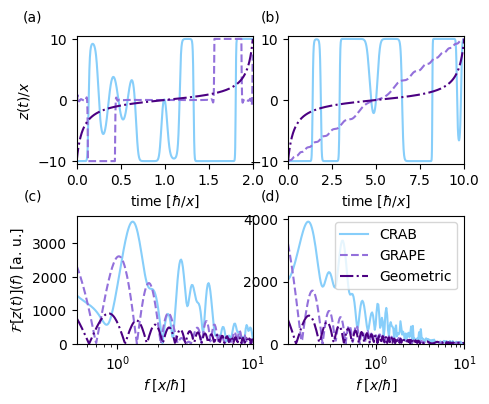

In [6]:
with mpl.rc_context({"lines.linewidth": 1.5}):
    fig, axs = plt.subplots(2, 2, figsize=(5, 4))

    for i in range(len(tfs_target)):
        time = np.linspace(0, tfs_target[i], n_ts, endpoint=False)
        hyper_time = np.linspace(0, tfs_target[i], len(geometric_pulse))

        axs[0, i].plot(time, CRAB_pulses[i], color=CRAB_color, label="CRAB")
        axs[0, i].plot(time, GRAPE_pulses[i], color=GRAPE_color, label="GRAPE", ls="--")
        axs[0, i].plot(
            hyper_time,
            geometric_pulse,
            color=geometric_color,
            label="Geometric",
            ls="-.",
        )

        axs[0, i].set_xlim(0, tfs_target[i])
        axs[0, i].set_ylim(-10.5, 10.5)
        axs[0, i].set_xlabel(r"time $[\hbar / x]$")

        ML_fs = 1 / (time[1] - time[0])
        hyper_fs = 1 / (hyper_time[1] - hyper_time[0])

        f_max = min(ML_fs, hyper_fs, 20) / 2
        f_min = max(1 / time[-1], 1 / hyper_time[-1])
        freqs = np.logspace(np.log10(f_min), np.log10(f_max), 200)

        CRAB_FFT = np.abs(fourier_at_freqs(CRAB_pulses[i], ML_fs, freqs))
        GRAPE_FFT = np.abs(fourier_at_freqs(GRAPE_pulses[i], ML_fs, freqs))
        hyper_FFT = np.abs(fourier_at_freqs(geometric_pulse, hyper_fs, freqs))

        axs[1, i].plot(freqs, CRAB_FFT, color=CRAB_color, label="CRAB")
        axs[1, i].plot(freqs, GRAPE_FFT, color=GRAPE_color, label="GRAPE", ls="--")
        axs[1, i].plot(
            freqs, hyper_FFT, color=geometric_color, label="Geometric", ls="-."
        )

        axs[1, i].set_xscale("log")
        axs[1, i].set_xlim(f_min, f_max)
        axs[1, i].set_ylim(0, None)
        axs[1, i].set_xlabel(r"$f \; [x / \hbar]$")

    axs[0, 0].set_ylabel(r"$z(t) / x$")
    axs[1, 0].set_ylabel(r"$\mathcal{F}[z(t)](f)$ [a. u.]")
    axs[1, 1].legend(frameon=True, loc="upper right")

    fig.subplots_adjust(hspace=0.4)
    add_labels(axs.flatten(), [[-0.25, 1.15], [-0.1, 1.15]] * 2)